In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


Демографические и социально-экономические признаки:

person_id – Уникальный идентификатор для каждого человека

age – Возраст индивидуума (18–90 лет)

sex – Пол (мужской/женский)

region – Географический регион

urban_rural – Проживает ли человек в городской или сельской местности

income – Годовой доход (долл. США)

education – Уровень образования

marital_status – Семейное положение

employment_status – Тип/статус занятости

household_size – Количество человек в домохозяйстве

dependents – Количество финансово иждивенцев

Образ жизни и привычки:

bmi – Значение индекса массы тела

smoker – Статус курения (Да/Нет)

alcohol_freq – Частота употребления алкоголя

Здоровье и показатели здоровья:

chronic_count – Количество диагностированных хронических заболеваний

hypertension – Показатель диагностированной гипертонии (0 = Нет, 1 = Да)

diabetes – Показатель диагностики диабета (0 = Нет, 1 = Да)

asthma – Показатель диагностики астмы (0 = Нет, 1 = Да)

copd – Показатель хронической обструктивной болезни легких (0 = нет, 1 = да)

cardiovascular – Наличие сердечно-сосудистых заболеваний (0 = Нет, 1 = Да)

cancer_history – История диагноза рака (0 = Нет, 1 = Да)

kidney_disease – Показатель хронической болезни почек (0 = Нет, 1 = Да)

liver_disease – Индикатор заболевания печени (0 = Нет, 1 = Да)

arthritis – Показатель для диагностики артрита (0 = Нет, 1 = Да)

mental_health – Наличие диагностированного психического расстройства (0 = Нет, 1 = Да)

systolic_bp – Систолическое артериальное давление (мм рт. ст.)

diastolic_bp – Диастолическое артериальное давление (мм рт. ст.)

ldl – Уровень холестерина ЛПНП (мг/дл)

hba1c – Процент гемоглобина A1c (показатель контроля уровня сахара в крови)

risk_score – Расчетный показатель риска для здоровья (нормализованный)

is_high_risk – Двоичный индикатор, если человек классифицируется как имеющий высокий риск для здоровья (0 = Нет, 1 = Да)

Использование медицинской помощи и процедуры:

visits_last_year – Количество посещений медицинских учреждений за последний год

hospitalizations_last_3yrs – Количество госпитализаций за последние три года

days_hospitalized_last_3yrs – Общее количество дней, проведенных в больнице за последние три года

medication_count – Количество назначенных активных лекарств

proc_imaging_count – Количество процедур с визуализацией (например, рентгенография, МРТ, КТ), выполненных в год

proc_surgery_count – Количество перенесенных хирургических операций

proc_physio_count – Количество психиатрических/психологических процедур или сеансов

proc_consult_count – Количество консультаций специалистов (например, кардиолога, онколога)

proc_lab_count – Количество проведенных лабораторных диагностических исследований

had_major_procedure – Индикатор, было ли у человека серьезное медицинское событие (например, операция, госпитализация)

Страхование и полис:

plan_type – Тип страхового плана (например, HMO, PPO, EPO)

network_tier – Сетевой уровень страковки (базовый, серебряный, золотой, платиновый)

deductible – Годовая сумма вычета в долларах США

copay – Сумма доплаты за услугу здравоохранения

policy_term_years – Срок действия страхового полиса в годах

policy_changes_last_2yrs – Количество изменений политики полиса за последние два года изменения полиса за последние 2 года

provider_quality – Рейтинг качества поставщика первичной медицинской помощи/страховщика

Медицинские расходы и страховые требования:

annual_medical_cost – Общие годовые медицинские расходы в долларах США (целевой признак)

annual_premium – Годовая страховая премия в долларах США

monthly_premium – Ежемесячная страховая премия в долларах США

claims_count – Количество страховых исков, поданных за год

avg_claim_amount – Средняя сумма иска в долларах США

total_claims_paid – Общая сумма претензий, выплаченных в долларах США

In [2]:
df = pd.read_csv('medical_insurance.csv')

In [3]:
df.isnull().sum()

person_id                          0
age                                0
sex                                0
region                             0
urban_rural                        0
income                             0
education                          0
marital_status                     0
employment_status                  0
household_size                     0
dependents                         0
bmi                                0
smoker                             0
alcohol_freq                   30083
visits_last_year                   0
hospitalizations_last_3yrs         0
days_hospitalized_last_3yrs        0
medication_count                   0
systolic_bp                        0
diastolic_bp                       0
ldl                                0
hba1c                              0
plan_type                          0
network_tier                       0
deductible                         0
copay                              0
policy_term_years                  0
p

In [4]:
df['alcohol_freq'] = df['alcohol_freq'].fillna('Not answered')

In [5]:
df['alcohol_freq'].value_counts()

alcohol_freq
Occasional      45078
Not answered    30083
Weekly          19833
Daily            5006
Name: count, dtype: int64

In [6]:
df.drop('person_id',axis=1, inplace=True)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 53 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   age                          100000 non-null  int64  
 1   sex                          100000 non-null  str    
 2   region                       100000 non-null  str    
 3   urban_rural                  100000 non-null  str    
 4   income                       100000 non-null  float64
 5   education                    100000 non-null  str    
 6   marital_status               100000 non-null  str    
 7   employment_status            100000 non-null  str    
 8   household_size               100000 non-null  int64  
 9   dependents                   100000 non-null  int64  
 10  bmi                          100000 non-null  float64
 11  smoker                       100000 non-null  str    
 12  alcohol_freq                 100000 non-null  str    
 13  visits_last

In [9]:
columns_already_unpacked = [col for col in df.columns if len(df[col].unique()) == 2]
columns_already_unpacked

['hypertension',
 'diabetes',
 'asthma',
 'copd',
 'cardiovascular_disease',
 'cancer_history',
 'kidney_disease',
 'liver_disease',
 'arthritis',
 'mental_health',
 'is_high_risk',
 'had_major_procedure']

In [68]:
df

,age,sex,region,urban_rural,income,education,marital_status,employment_status,household_size,dependents,...,liver_disease,arthritis,mental_health,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count,is_high_risk,had_major_procedure
0,52,Female,North,Suburban,22700.0,Doctorate,Married,Retired,3,1,...,0,1,0,1,0,2,0,1,0,0
1,79,Female,North,Urban,12800.0,No HS,Married,Employed,3,1,...,0,1,1,0,0,1,0,1,1,0
2,68,Male,North,Rural,40700.0,HS,Married,Retired,5,3,...,0,0,1,1,0,2,1,0,1,0
3,15,Male,North,Suburban,15600.0,Some College,Married,Self-employed,5,3,...,0,0,0,1,0,0,1,0,0,0
4,53,Male,Central,Suburban,89600.0,Doctorate,Married,Self-employed,2,0,...,0,1,0,2,0,1,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,50,Male,West,Urban,127200.0,No HS,Married,Employed,2,0,...,0,0,0,0,0,1,0,0,0,0
99996,42,Male,East,Suburban,21600.0,HS,Married,Employed,2,0,...,0,0,0,0,0,0,0,0,0,0
99997,41,Male,West,Rural,81900.0,HS,Divorced,Unemployed,1,0,...,0,0,0,1,0,1,0,0,0,0
99998,51,Female,South,Urban,43400.0,Doctorate,Single,Unemployed,3,2,...,0,0,1,0,0,2,2,1,0,0


In [69]:
df.drop(columns_already_unpacked + list(df.select_dtypes('str').columns), axis=1).describe().drop('count')

,age,income,household_size,dependents,bmi,visits_last_year,hospitalizations_last_3yrs,days_hospitalized_last_3yrs,medication_count,systolic_bp,...,monthly_premium,claims_count,avg_claim_amount,total_claims_paid,chronic_count,proc_imaging_count,proc_surgery_count,proc_physio_count,proc_consult_count,proc_lab_count
mean,47.521500,4.987390e+04,2.430900,0.898380,26.990512,1.92765,0.093640,0.373350,1.236320,117.808970,...,48.526668,1.62178,656.512084,1377.878827,0.724720,0.508530,0.158690,0.508390,0.50933,0.509140
std,15.988752,4.680021e+04,1.075126,0.950654,4.994883,1.73773,0.304848,1.373011,1.209358,15.369187,...,33.298640,2.02982,1072.660048,2305.464687,0.805523,0.749755,0.463562,0.747218,0.75363,0.750455
min,0.000000,1.100000e+03,1.000000,0.000000,12.000000,0.00000,0.000000,0.000000,0.000000,61.000000,...,17.640000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
25%,37.000000,2.110000e+04,2.000000,0.000000,23.600000,1.00000,0.000000,0.000000,0.000000,107.000000,...,29.340000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000
50%,48.000000,3.620000e+04,2.000000,1.000000,27.000000,2.00000,0.000000,0.000000,1.000000,117.000000,...,38.630000,1.00000,318.015000,642.545000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000
75%,58.000000,6.220000e+04,3.000000,1.000000,30.400000,3.00000,0.000000,0.000000,2.000000,128.000000,...,55.560000,2.00000,872.215000,1795.522500,1.000000,1.000000,0.000000,1.000000,1.00000,1.000000
max,100.000000,1.061800e+06,9.000000,7.000000,50.400000,25.00000,3.000000,21.000000,11.000000,183.000000,...,913.550000,23.00000,30010.530000,72517.950000,6.000000,7.000000,6.000000,7.000000,7.00000,7.000000


In [ ]:
plt.figure(figsize=(14,12))
for i,col in enumerate(columns_already_unpacked):
    plt.subplot(3, 4, i+1)
    sns.boxplot(df[col])
plt.tight_layout()

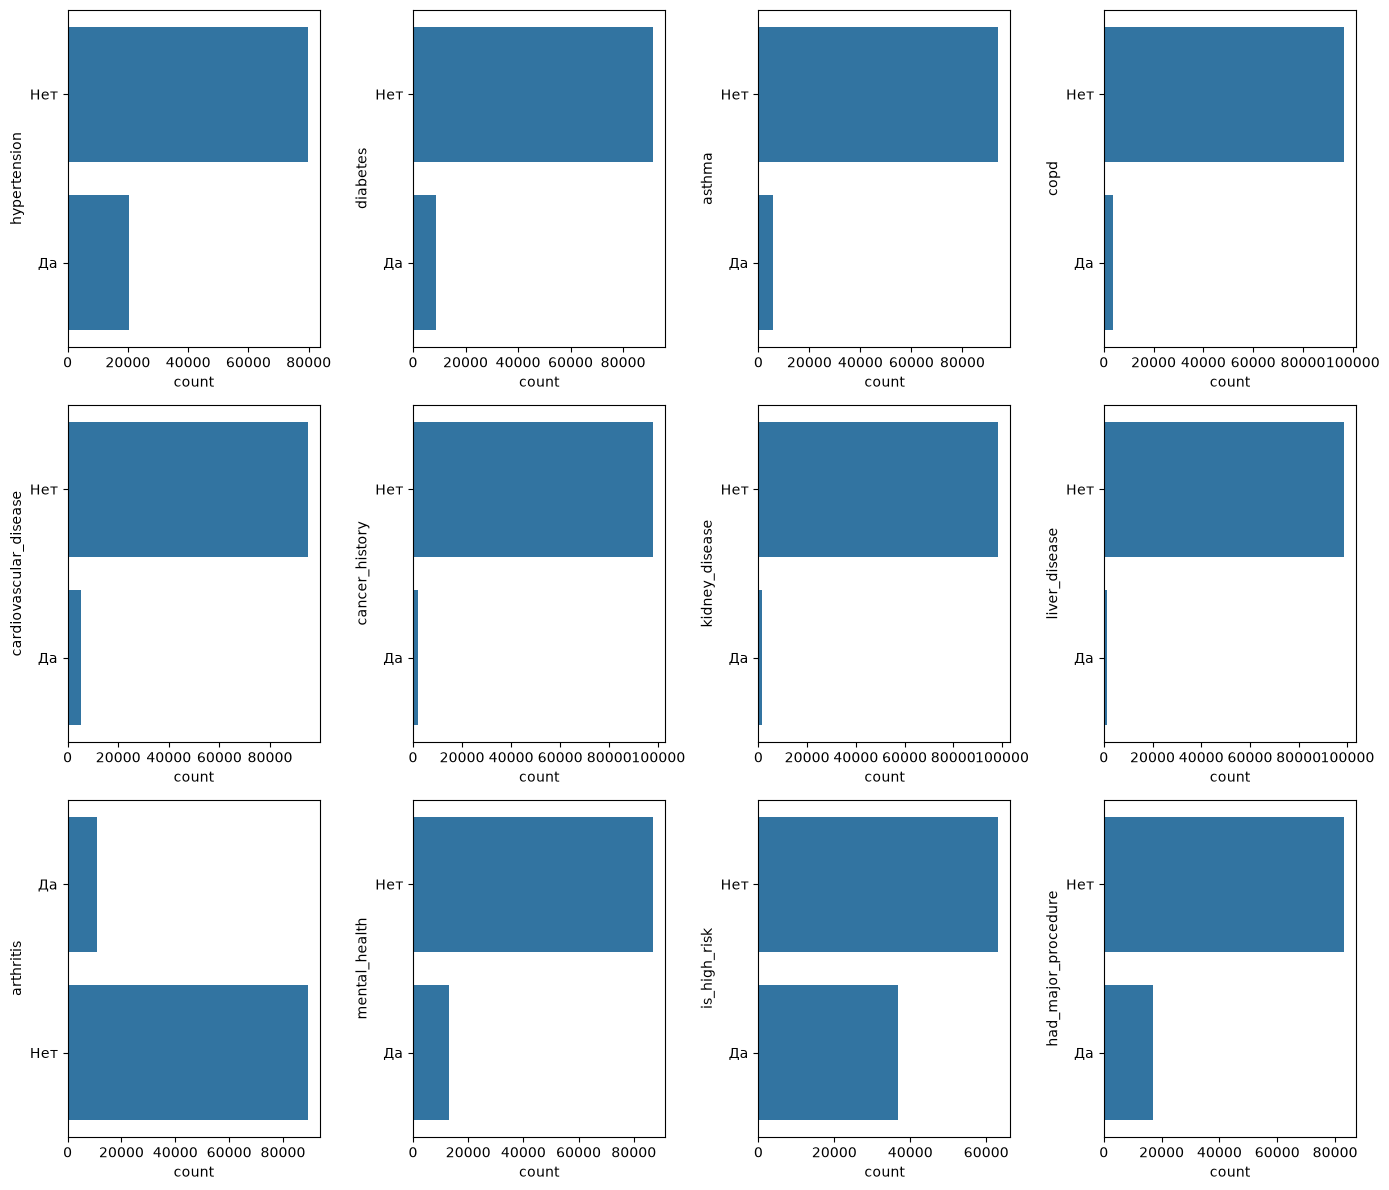

In [10]:
plt.figure(figsize=(14,12))
for i,col in enumerate(columns_already_unpacked):
    plt.subplot(3, 4, i+1)
    sns.countplot(df[col].map({1: 'Да', 0:'Нет'}))
plt.tight_layout()

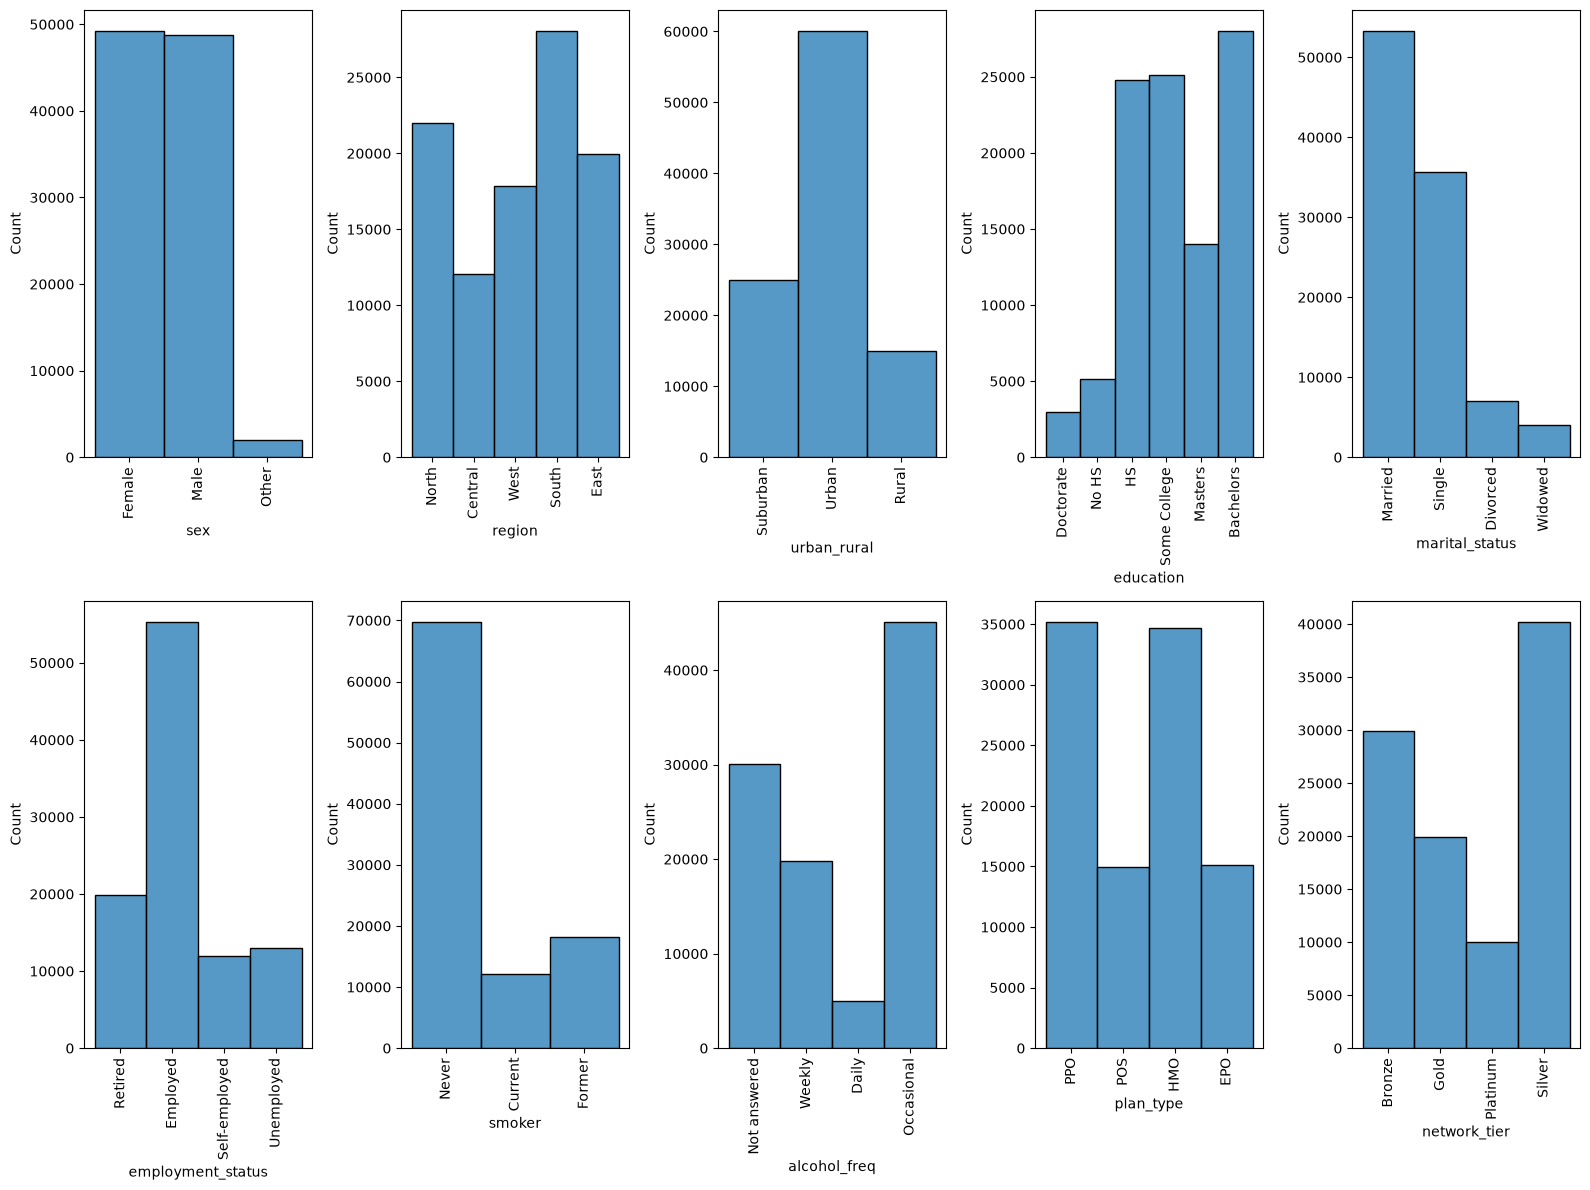

In [11]:
plt.figure(figsize=(16,12))
for i,col in enumerate(df.select_dtypes('str').columns):
    plt.subplot(2, 5, i+1)
    sns.histplot(df[col])
    plt.xticks(rotation=90)
plt.tight_layout()

<Axes: xlabel='annual_medical_cost', ylabel='Count'>

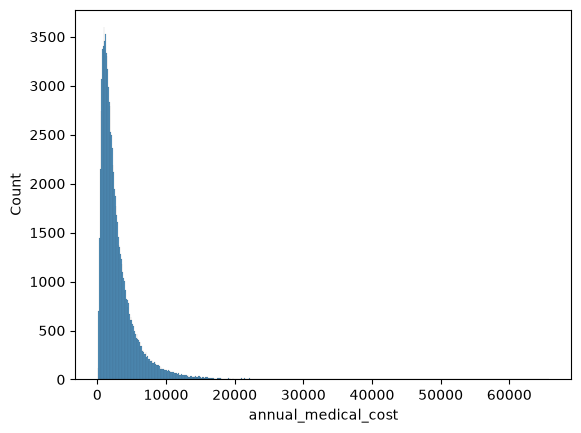

In [12]:
sns.histplot(df['annual_medical_cost'])

In [13]:
import phik
from phik import significance_matrix

In [14]:
correlation_for_depended = pd.DataFrame(df.phik_matrix(interval_cols=df.select_dtypes(['float64', 'int64']))['annual_medical_cost'].drop('annual_medical_cost').sort_values(), columns=['annual_medical_cost'])

<Axes: >

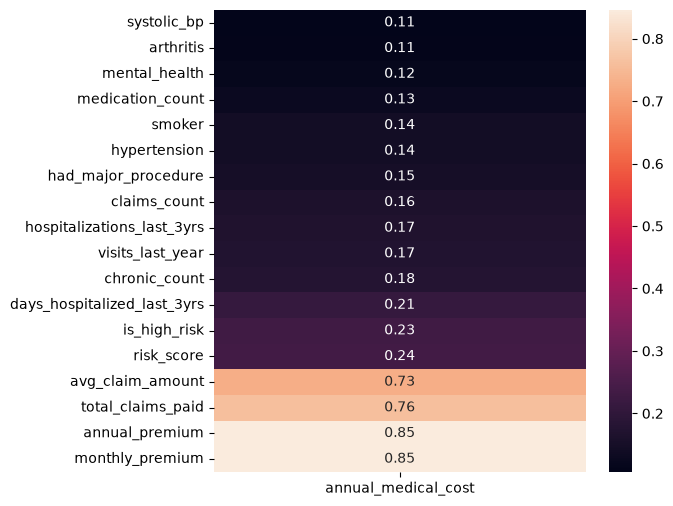

In [15]:
plt.figure(figsize=(6,6))
sns.heatmap(correlation_for_depended[correlation_for_depended['annual_medical_cost'] > 0.1], annot=True)

In [16]:
significance = df[list(df.select_dtypes('str').columns) + columns_already_unpacked + ['annual_medical_cost']].significance_matrix()

interval columns not set, guessing: ['hypertension', 'diabetes', 'asthma', 'copd', 'cardiovascular_disease', 'cancer_history', 'kidney_disease', 'liver_disease', 'arthritis', 'mental_health', 'is_high_risk', 'had_major_procedure', 'annual_medical_cost']


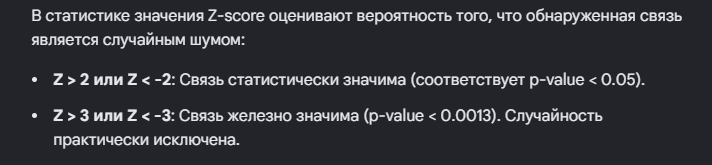

In [17]:
significance_of_nominiative_variables_for_depended = abs(significance['annual_medical_cost']).drop('annual_medical_cost')[abs(significance['annual_medical_cost']) > 2]

In [18]:
significance_of_nominiative_variables_for_depended

smoker                    33.418632
hypertension              31.866439
diabetes                  20.975077
asthma                    15.714678
copd                      13.097361
cardiovascular_disease    15.888731
cancer_history            10.408327
kidney_disease             9.253347
liver_disease              9.206697
arthritis                 23.992394
mental_health             25.470397
is_high_risk              54.674422
had_major_procedure       32.713655
Name: annual_medical_cost, dtype: float64

In [19]:
true_cont_variables = df.select_dtypes(['float64', 'int64']).drop(columns_already_unpacked,axis=1).columns
significance_continuous= df[true_cont_variables].significance_matrix(interval_cols=true_cont_variables)

In [20]:
significance_of_conitnious_variables_for_depended = abs(significance_continuous['annual_medical_cost']).drop('annual_medical_cost')[abs(significance_continuous['annual_medical_cost']) > 2]

In [21]:
significance_of_conitnious_variables_for_depended

age                             23.184455
bmi                              2.744623
visits_last_year                37.610147
hospitalizations_last_3yrs      43.157980
days_hospitalized_last_3yrs     44.901270
medication_count                20.377561
systolic_bp                     26.811814
diastolic_bp                    21.617692
hba1c                           16.013685
risk_score                      64.047400
annual_premium                 172.592000
monthly_premium                172.610959
claims_count                    32.952998
avg_claim_amount               109.539211
total_claims_paid              123.049087
chronic_count                   62.665332
proc_imaging_count              12.253882
proc_surgery_count              17.178951
proc_physio_count                9.570059
proc_consult_count              11.136934
proc_lab_count                  11.318600
Name: annual_medical_cost, dtype: float64

In [22]:
len(df.columns) - len(df[list(significance_of_conitnious_variables_for_depended.index) + list(significance_of_nominiative_variables_for_depended.index)].columns)

19

In [56]:
df_changed = df[list(significance_of_conitnious_variables_for_depended.index) + list(significance_of_nominiative_variables_for_depended.index) + ['annual_medical_cost']]

In [57]:
df_changed.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 35 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   age                          100000 non-null  int64  
 1   bmi                          100000 non-null  float64
 2   visits_last_year             100000 non-null  int64  
 3   hospitalizations_last_3yrs   100000 non-null  int64  
 4   days_hospitalized_last_3yrs  100000 non-null  int64  
 5   medication_count             100000 non-null  int64  
 6   systolic_bp                  100000 non-null  float64
 7   diastolic_bp                 100000 non-null  float64
 8   hba1c                        100000 non-null  float64
 9   risk_score                   100000 non-null  float64
 10  annual_premium               100000 non-null  float64
 11  monthly_premium              100000 non-null  float64
 12  claims_count                 100000 non-null  int64  
 13  avg_claim_a

In [64]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


In [49]:
X = df_changed.drop('annual_medical_cost', axis=1)
y = df_changed['annual_medical_cost']

In [58]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [65]:
# Определяем группы колонок
cols_to_scale = [c for c in X.columns if c not in columns_already_unpacked + ['smoker']]
cols_to_dummify = ['smoker']
cols_to_keep = columns_already_unpacked  # уже распакованные дамми

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), cols_to_scale),           # масштабируем числовые
        ('cat', OneHotEncoder(drop='first'), cols_to_dummify),  # smoker → дамми
        ('passthrough', 'passthrough', cols_to_keep)        # оставляем как есть
    ],
    remainder='drop'
)

# Применяем
X_train_final = preprocessor.fit_transform(X_train)
X_test_final = preprocessor.transform(X_test)


feature_names = (
    cols_to_scale +
    list(preprocessor.named_transformers_['cat'].get_feature_names_out(['smoker'])) +
    cols_to_keep
)